# Trait specificity by receiver model: treatment vs. its matched trait-free control

A **dog** teacher's numbers, distilled into students, raise $p(\texttt{dog})$ -- and a cat, lion or
pig teacher's numbers raise that teacher's animal. Does anything else move? This notebook answers
that per teacher trait and receiving init, against the control that makes the question
well posed: the same student cells distilled from numbers generated by the *untuned* sender base
(`controls/base/...`), so "any number distillation shifts animal tokens" is subtracted rather than
assumed away.

**Design.** 10 teachers per trait (`run_logs/dog_top10_kband_configs.json` param tags, tseed 1 --
the same 10 configs for all four traits) $\times$ 30 student cells (`run_logs/core30_cells.json`),
ftseed 1, pool `ex10-20_prefix_n100k`, three arms:

| condition | trait | receiver / sender | animals | readout |
|---|---|---|---|---|
| same-model | dog | receiver = sender $\in$ orig, fs1, fs2, fs3 | ten | endpoint row of `eval/pref_traj.json` |
| same-model | cat, lion, pig | receiver = sender $\in$ orig, fs1, fs2, fs3 | ten | endpoint row of `eval/pref_endpoint10.json` |
| cross-model | dog | 12 ordered pairs over those four inits | dog, cat, lion, pig | `preference_summary.json` (`test`) |
| cross-data-order | dog | receiver ds1, sender orig | ten | endpoint row of `eval/pref_traj.json` |

The trait-free controls (`controls/base/<receiver>/teacher-<sender>/`) are shared: they contain no
trait, so the same control runs serve all four traits.

**The statistic** (a difference of means -- not a new metric). For each (trait, receiver model,
condition, animal): **effect = mean over treatment runs of $p_a$ $-$ mean over control runs of
$p_a$**, in probability units. Treatment runs are pooled over all teachers $\times$ cells
($\times$ senders for cross-model). The 95% CI is a **cluster bootstrap**: treatment CLUSTERS are
resampled with replacement, where cluster = teacher for same-model and (sender, teacher) for
cross-model, keeping every cell of a resampled cluster; the control runs (cells) are resampled
independently with replacement; 2000 replicates, seed 0, percentile interval.

## 1. Load + coverage

In [1]:
import pandas as pd

from subliminal_learning.analysis import trait_specificity as ts
from subliminal_learning.analysis.setup import bootstrap, set_plot_style

set_plot_style(dpi=115, hide_spines=True)
pd.set_option("display.width", 250)
ROOT, OUTPUT_ROOT = bootstrap()

runs = ts.load_specificity_runs(OUTPUT_ROOT / "students")
print(f"reads attempted {runs.attrs['n_jobs']} | unreadable runs {runs.attrs['n_missing']} | "
      f"rows (run x animal) {len(runs)}")
print("Row unit = one run (arm x trait x receiver x condition); n_runs = teachers x senders x cells.")
print("A still-filling queue shows up here as n_runs < 300 for a (trait, receiver) treatment row.")
display(ts.coverage(runs))

reads attempted 9570 | unreadable runs 0 | rows (run x animal) 140580
Row unit = one run (arm x trait x receiver x condition); n_runs = teachers x senders x cells.
A still-filling queue shows up here as n_runs < 300 for a (trait, receiver) treatment row.


,trait,receiver,condition,arm,n_runs,n_senders,n_teachers,n_cells
0,cat,fs1,same-model,control,30,1,1,30
1,cat,fs1,same-model,treatment,300,1,10,30
2,cat,fs2,same-model,control,30,1,1,30
3,cat,fs2,same-model,treatment,300,1,10,30
4,cat,fs3,same-model,control,30,1,1,30
5,cat,fs3,same-model,treatment,300,1,10,30
6,cat,orig,same-model,control,30,1,1,30
7,cat,orig,same-model,treatment,300,1,10,30
8,dog,ds1,cross-data-order,control,30,1,1,30
9,dog,ds1,cross-data-order,treatment,300,1,10,30


## 2. The table

Rows = trait $\times$ receiver model $\times$ condition, columns = the ten animals (the row's own
trait is the target), cell = `diff [lo, hi]` from §0's statistic, in probability units at three
significant figures. `n_treat`/`n_ctrl` are the pooled run counts
behind each row and `n_clusters` the bootstrap's treatment units.

In [2]:
summary = ts.summarize(runs, n_boot=2000, seed=0, stat="diff")
display(ts.summary_table(summary))

dog                              cat                              lion                              pig                            rabbit                           chicken  \
trait receiver condition                                                                                                                                                                                                                
dog   orig     same-model                0.611 [0.568, 0.655]       0.0005 [-2.8e-05, 0.00103]         -0.015 [-0.0195, -0.0112]    -0.00572 [-0.00716, -0.00437]     -0.00594 [-0.00765, -0.00437]     -0.00289 [-0.00351, -0.00225]   
               cross-model            0.0419 [0.0297, 0.0557]      0.00119 [0.000346, 0.00218]    -0.00119 [-0.00228, -0.000135]   -0.00108 [-0.00179, -0.000354]                                 -                                 -   
      fs1      same-model                 0.525 [0.47, 0.575]   -0.00199 [-0.00357, -0.000424]   -0.000361 [-0.000504, -0.00023]   -0.00156 [-0.00241, -0.000807]      -0.00129 [-0.00172, -0.0009]    -0.00163 [-0.00227, -0.000998]   
               cross-model         0.00459 [0.00154, 0.00807]  -0.000331 [-0.000754, 8.17e-05]     0.000219 [2.05e-05, 0.000442]   0.000209 [-0.000148, 0.000634]                                 -                                 -   
      fs2      same-model                0.188 [0.154, 0.224]        0.00693 [0.00458, 0.0103]    -0.00143 [-0.00195, -0.000875]     0.000713 [0.000321, 0.00119]    0.000116 [-7.62e-05, 0.000318]    -0.00074 [-0.00104, -0.000438]   
               cross-model         0.00385 [0.00233, 0.00544]       0.00365 [0.00222, 0.00523]    -0.00021 [-0.000746, 0.000278]   9.88e-05 [-9.67e-05, 0.000288]                                 -                                 -   
      fs3      same-model                0.536 [0.454, 0.608]    -0.00596 [-0.00923, -0.00307]       -0.00279 [-0.00369, -0.002]    -0.00283 [-0.00389, -0.00189]   -0.000713 [-0.00122, -0.000254]   -0.000412 [-0.00067, -0.000181]   
               cross-model           0.0098 [0.00504, 0.0154]    0.000832 [-0.000105, 0.00181]    -0.000231 [-0.00061, 0.000147]  -0.000166 [-0.000429, 0.000118]                                 -                                 -   
      ds1      cross-data-order       0.0327 [0.0198, 0.0477]  -0.000893 [-0.00176, -0.000147]      -0.0037 [-0.00581, -0.00175]  -0.000822 [-0.00127, -0.000432]    -0.000258 [-0.00101, 0.000438]   -0.00028 [-0.000526, -3.81e-05]   
cat   orig     same-model         0.00534 [0.000654, 0.00954]             0.284 [0.227, 0.348]       -0.0127 [-0.0173, -0.00895]     -0.0051 [-0.00657, -0.00376]     -0.00444 [-0.00618, -0.00282]     -0.00258 [-0.00321, -0.00191]   
      fs1      same-model          0.00617 [-0.00109, 0.0135]             0.314 [0.263, 0.362]  -0.000365 [-0.000504, -0.000238]    -0.00117 [-0.00203, -0.00042]     -0.0008 [-0.00123, -0.000401]    -0.00152 [-0.00211, -0.000938]   
      fs2      same-model             0.0174 [0.0117, 0.0245]            0.124 [0.0971, 0.153]    -6.5e-05 [-0.000917, 0.000846]       0.00163 [0.00106, 0.00243]     0.000442 [0.000249, 0.000643]    1.48e-05 [-0.000422, 0.000528]   
      fs3      same-model        6.53e-05 [-0.00828, 0.00787]             0.468 [0.399, 0.535]    -0.00144 [-0.00248, -0.000487]    -0.00266 [-0.00372, -0.00169]   -0.000738 [-0.00121, -0.000281]  -0.000367 [-0.000629, -0.000117]   
lion  orig     same-model        -0.00623 [-0.0106, -0.00285]  -0.000269 [-0.000609, 4.65e-05]              0.516 [0.469, 0.566]    -0.00556 [-0.00701, -0.00424]     -0.00579 [-0.00751, -0.00425]     -0.00229 [-0.00296, -0.00162]   
      fs1      same-model         -0.0102 [-0.0157, -0.00503]    -0.00332 [-0.00462, -0.00214]              0.323 [0.264, 0.379]     -0.00182 [-0.00266, -0.0011]      -0.00148 [-0.00189, -0.0011]     -0.00211 [-0.00268, -0.00155]   
      fs2      same-model          0.00229 [0.000147, 0.0047]       0.00265 [0.00139, 0.00406]   

## 3. Figures -- per animal

First the dog arms on one chart: x = the ten animals (dog = the teacher's trait, first), y =
treatment $-$ control in probability units on a **linear** axis, so dog's 0.1-0.7 lift and the
non-targets' near-zero moves share one scale. Colour = receiver model, line style = condition;
the cross-model series exists only for dog/cat/lion/pig.

wrote /home/angela/EleutherAI_subliminal_learning/notebooks/figures/trait_specificity_by_model.png


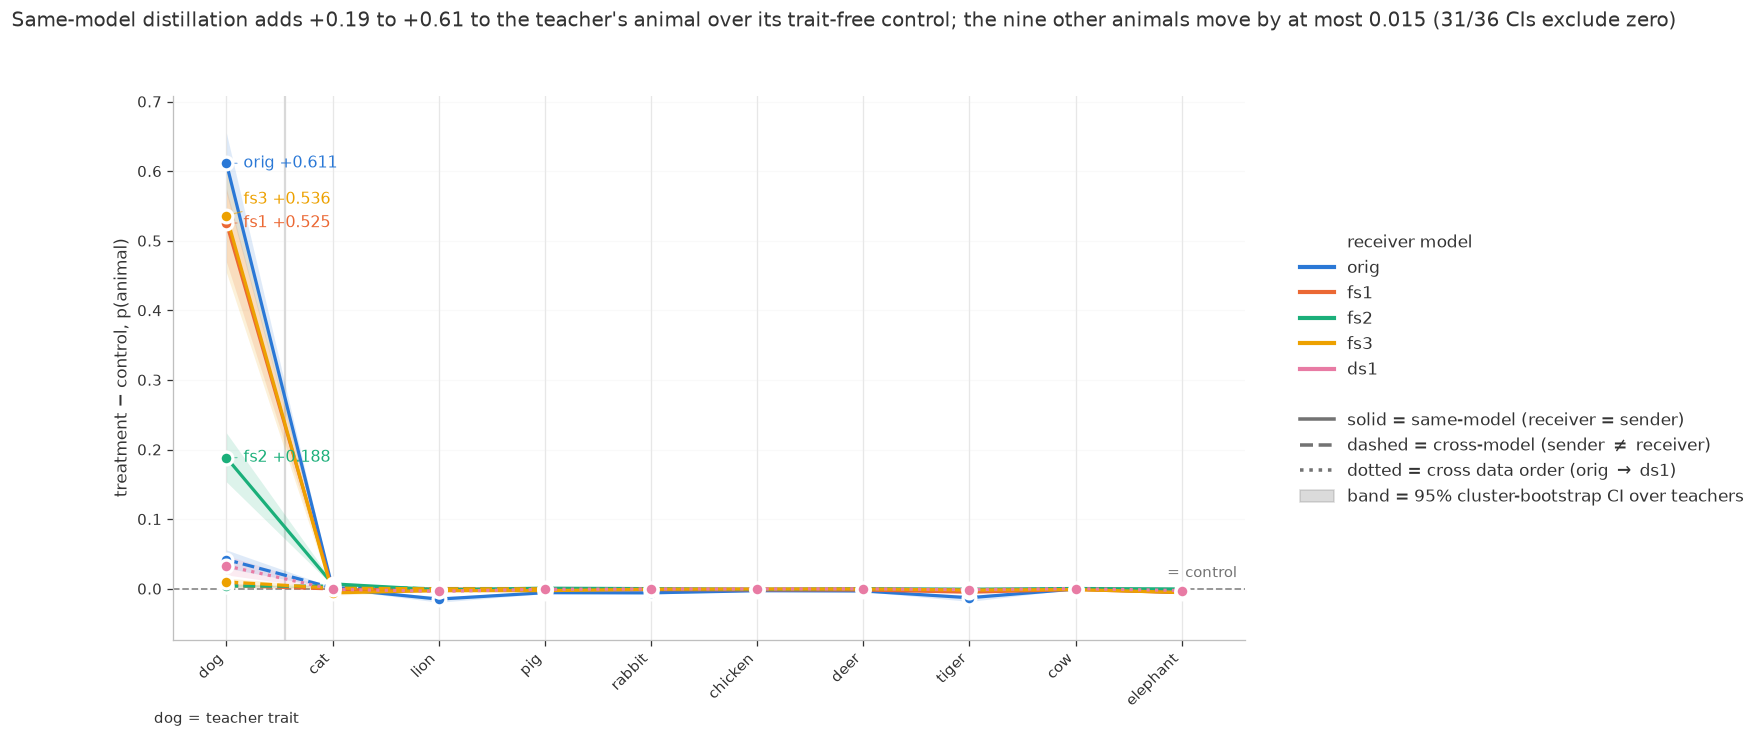

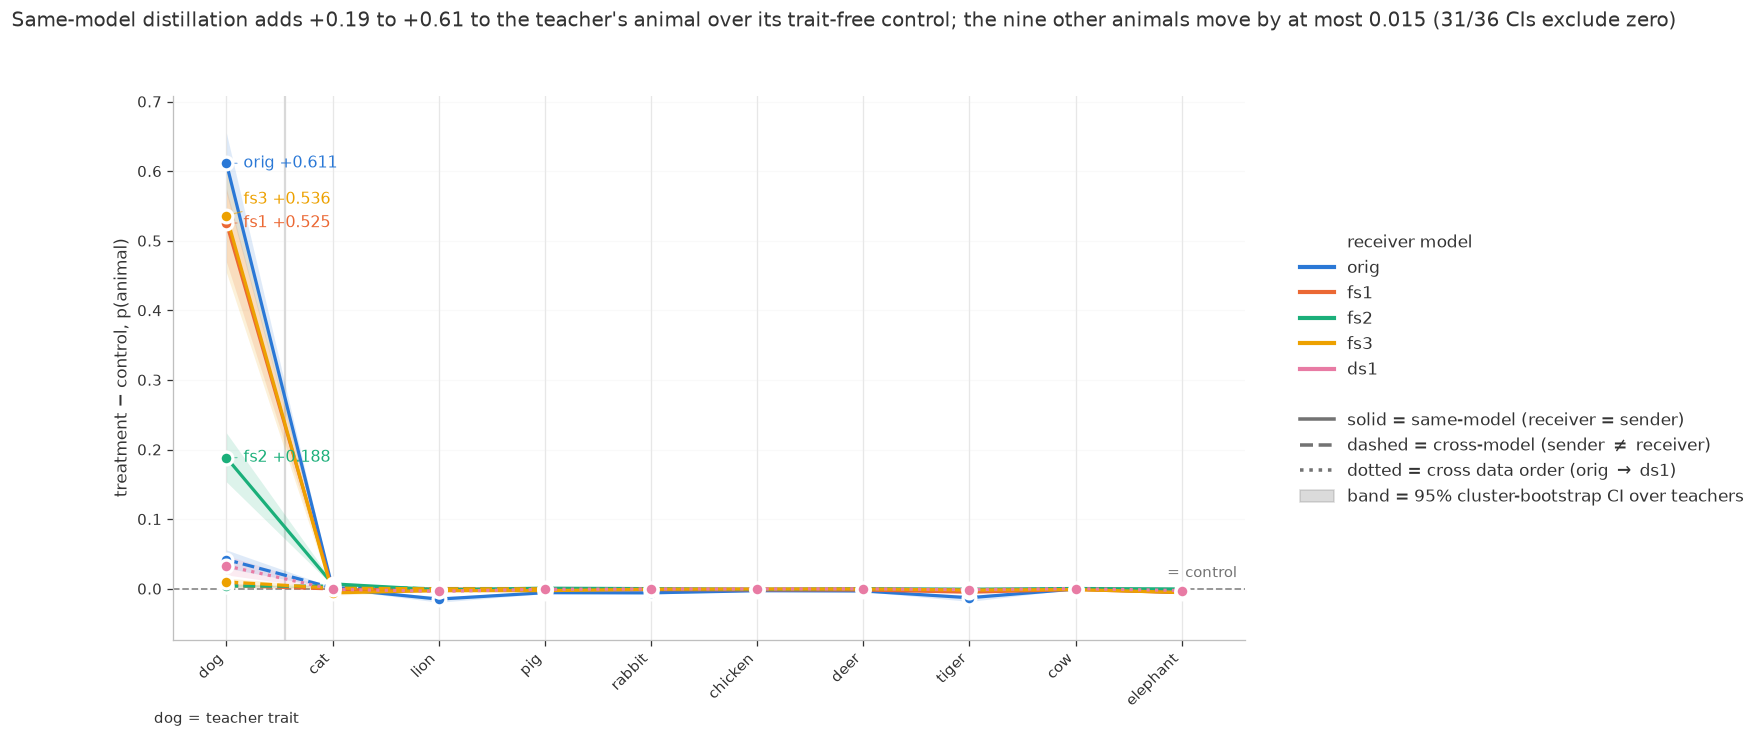

In [3]:
PNG = ROOT / "notebooks" / "figures" / "trait_specificity_by_model.png"
fig = ts.plot_by_model(summary, PNG)
print(f"wrote {PNG}")
fig

Then the four traits, same-model only: one panel per teacher trait, that trait's own animal first
on the x axis, colour = receiver init. Same statistic, same bands.

wrote /home/angela/EleutherAI_subliminal_learning/notebooks/figures/trait_specificity_by_trait.png


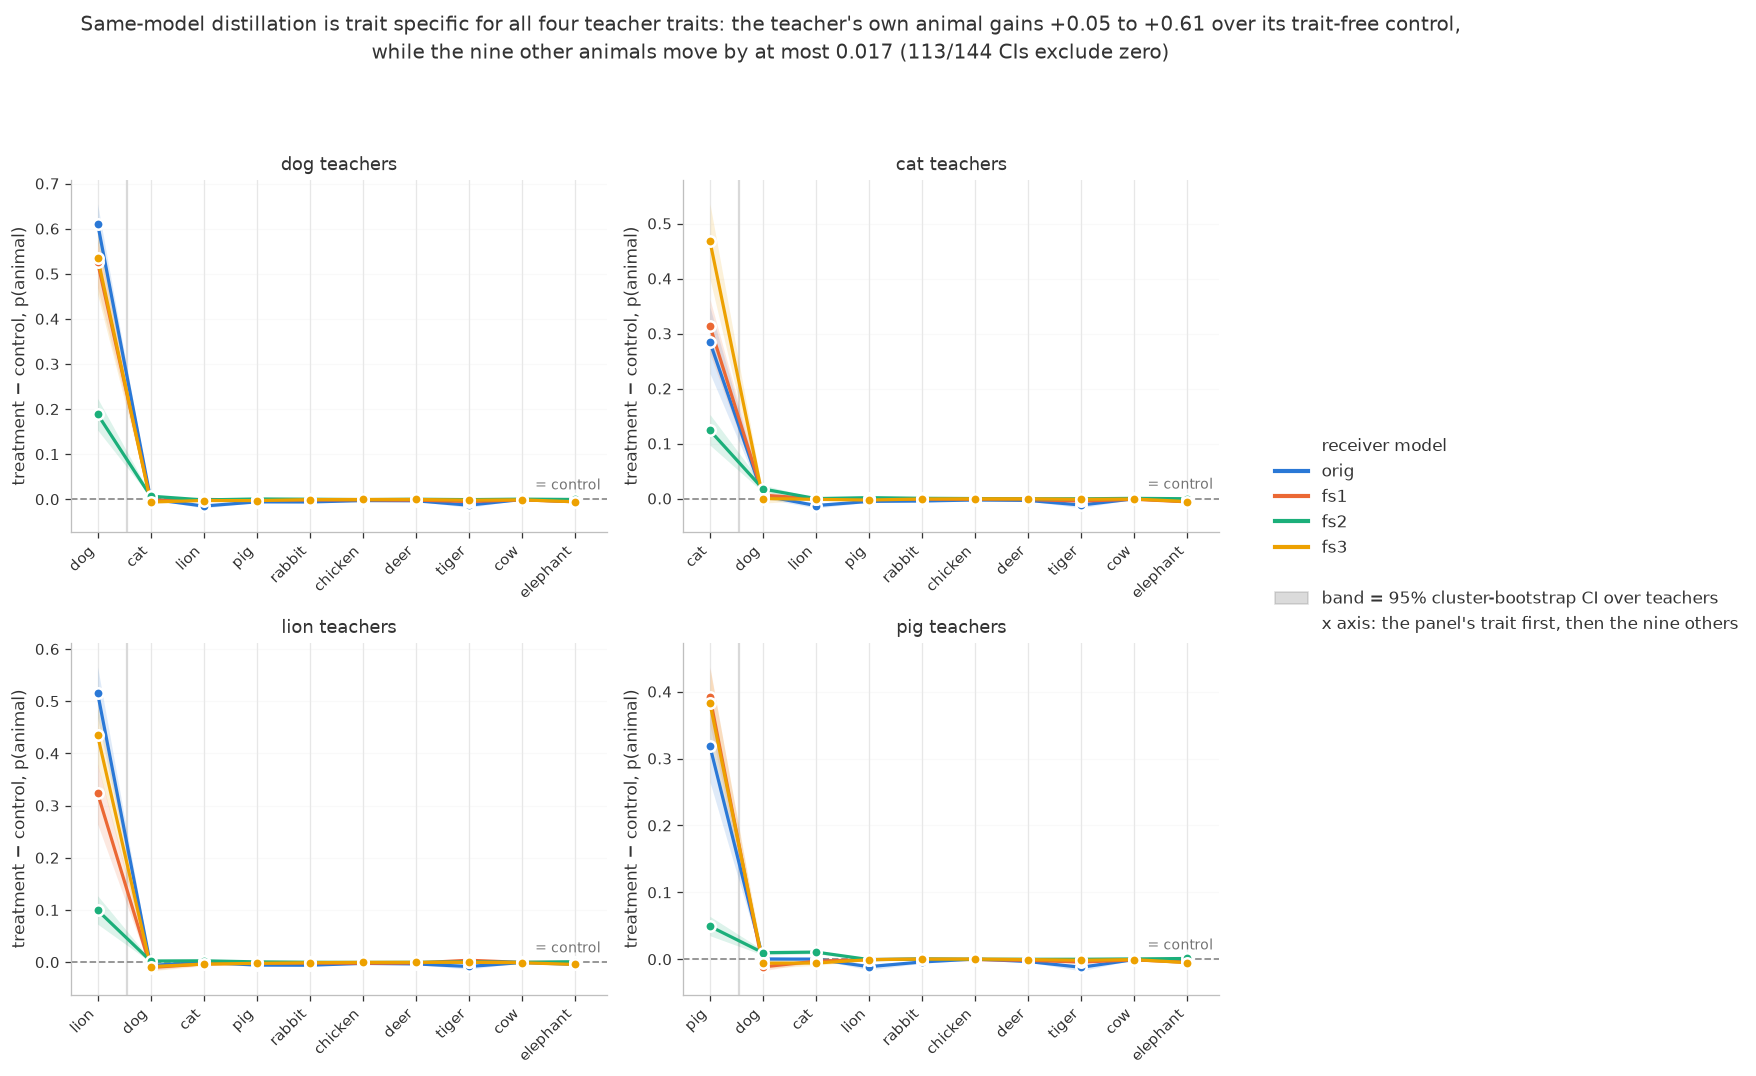

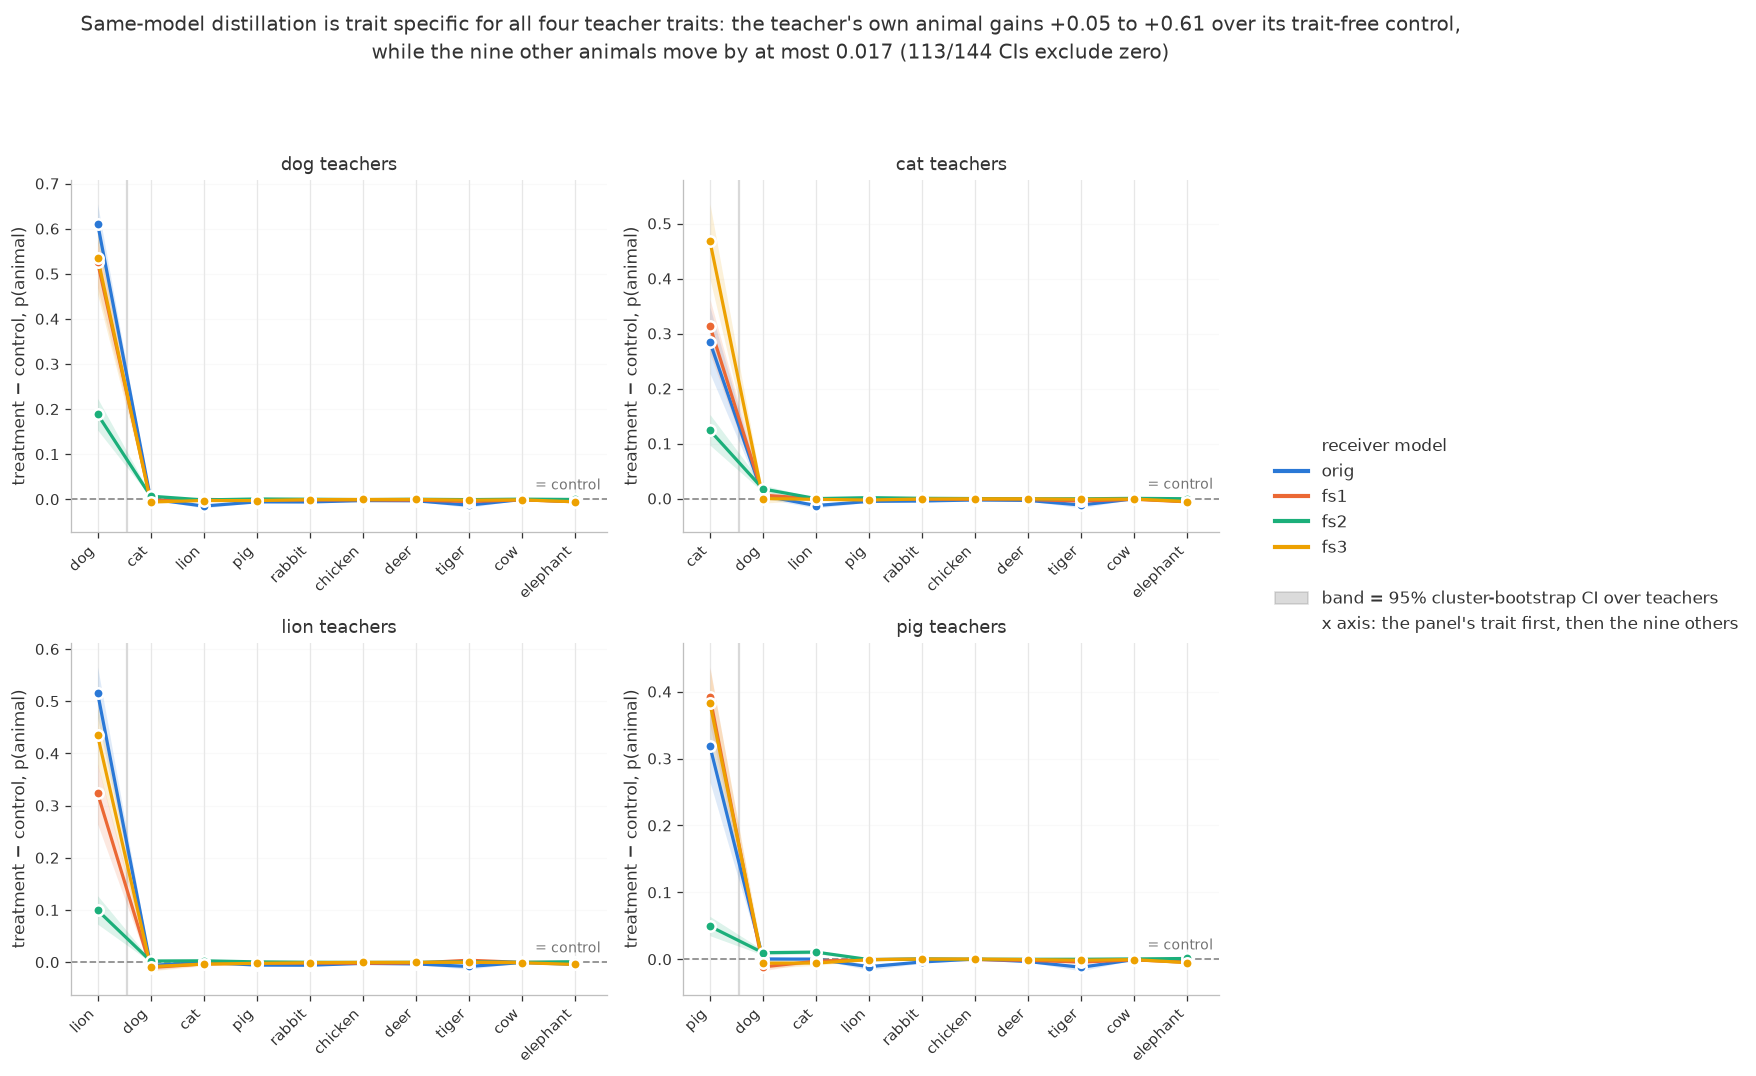

In [4]:
PNG3 = ROOT / "notebooks" / "figures" / "trait_specificity_by_trait.png"
fig3 = ts.plot_by_model_traits(summary, PNG3)
print(f"wrote {PNG3}")
fig3

## 4. Aggregate: teacher trait vs. the other animals

Per run, two scalars: $p_\text{trait}$ = the probability of the run's **own** teacher animal, and
$p_\text{others}$ = the mean over the non-target animals **scored for that run**. That set is
asymmetric by arm: nine animals for same-model and cross-data-order, but only cat/lion/pig for
dog cross-model (the arm was re-scored on four animals), so that row averages three animals, not
nine. Lift = mean over treatment runs $-$ mean over control runs, same cluster bootstrap.

The figure below shows the same-model rows only -- one colour per trait, solid = own trait, dashed
= the nine others. The dog cross-model / cross-data-order rows stay in the table.

In [5]:
lifts = ts.summarize_trait_vs_others(runs, n_boot=2000, seed=0)
display(ts.lift_table(lifts))

quantity                                              trait                          others
trait receiver condition                                                                   
dog   orig     same-model              0.611 [0.568, 0.655]   -0.00567 [-0.00686, -0.00453]
               cross-model           0.0419 [0.0299, 0.056]  -0.000359 [-0.00107, 0.000375]
      fs1      same-model              0.525 [0.469, 0.574]   -0.00226 [-0.00297, -0.00162]
               cross-model       0.00459 [0.00143, 0.00799]  3.25e-05 [-0.000189, 0.000265]
      fs2      same-model              0.188 [0.153, 0.223]    0.000541 [5.46e-05, 0.00124]
               cross-model       0.00385 [0.00224, 0.00541]      0.00118 [0.000575, 0.0018]
      fs3      same-model              0.536 [0.455, 0.609]   -0.00241 [-0.00321, -0.00169]
               cross-model          0.0098 [0.00513, 0.015]  0.000145 [-0.000278, 0.000615]
      ds1      cross-data-order     0.0327 [0.0195, 0.0474]  -0.00108 [-0.00173, -0.000476]
cat   orig     same-model              0.284 [0.228, 0.348]   -0.00444 [-0.00568, -0.00323]
      fs1      same-model              0.314 [0.263, 0.363]  -0.00126 [-0.00231, -0.000167]
      fs2      same-model             0.124 [0.0971, 0.153]      0.00208 [0.00132, 0.00293]
      fs3      same-model              0.468 [0.399, 0.535]  -0.00146 [-0.00272, -0.000247]
lion  orig     same-model              0.516 [0.469, 0.566]   -0.00404 [-0.00496, -0.00315]
      fs1      same-model              0.323 [0.264, 0.379]   -0.00199 [-0.00315, -0.00089]
      fs2      same-model             0.0994 [0.073, 0.127]    0.000664 [0.000301, 0.00103]
      fs3      same-model               0.434 [0.377, 0.49]  -0.00239 [-0.00393, -0.000834]
pig   orig     same-model              0.318 [0.265, 0.371]   -0.00362 [-0.00488, -0.00236]
      fs1      same-model               0.392 [0.35, 0.437]   -0.00285 [-0.00393, -0.00179]
      fs2      same-model           0.0493 [0.0353, 0.0641]      0.00251 [0.00162, 0.00347]
      fs3      same-model              0.382 [0.332, 0.434]   -0.00203 [-0.0036, -0.000526]

wrote /home/angela/EleutherAI_subliminal_learning/notebooks/figures/trait_vs_others_lift_by_model.png


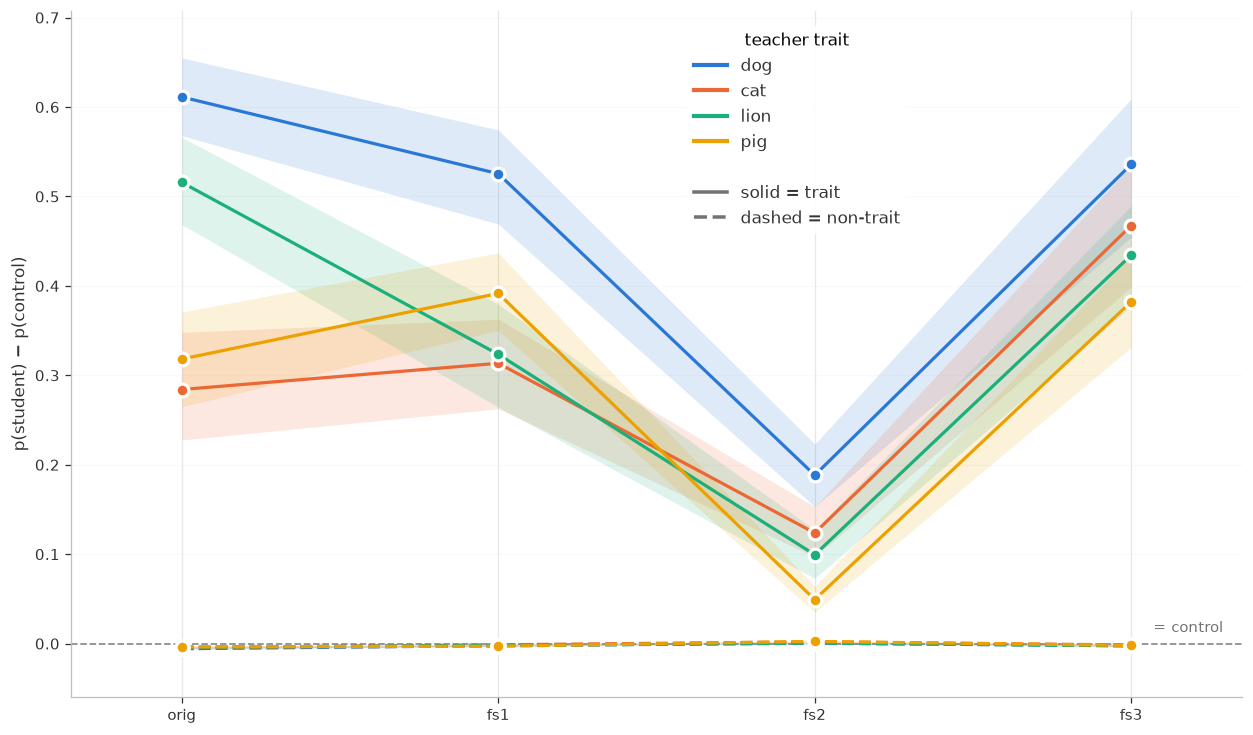

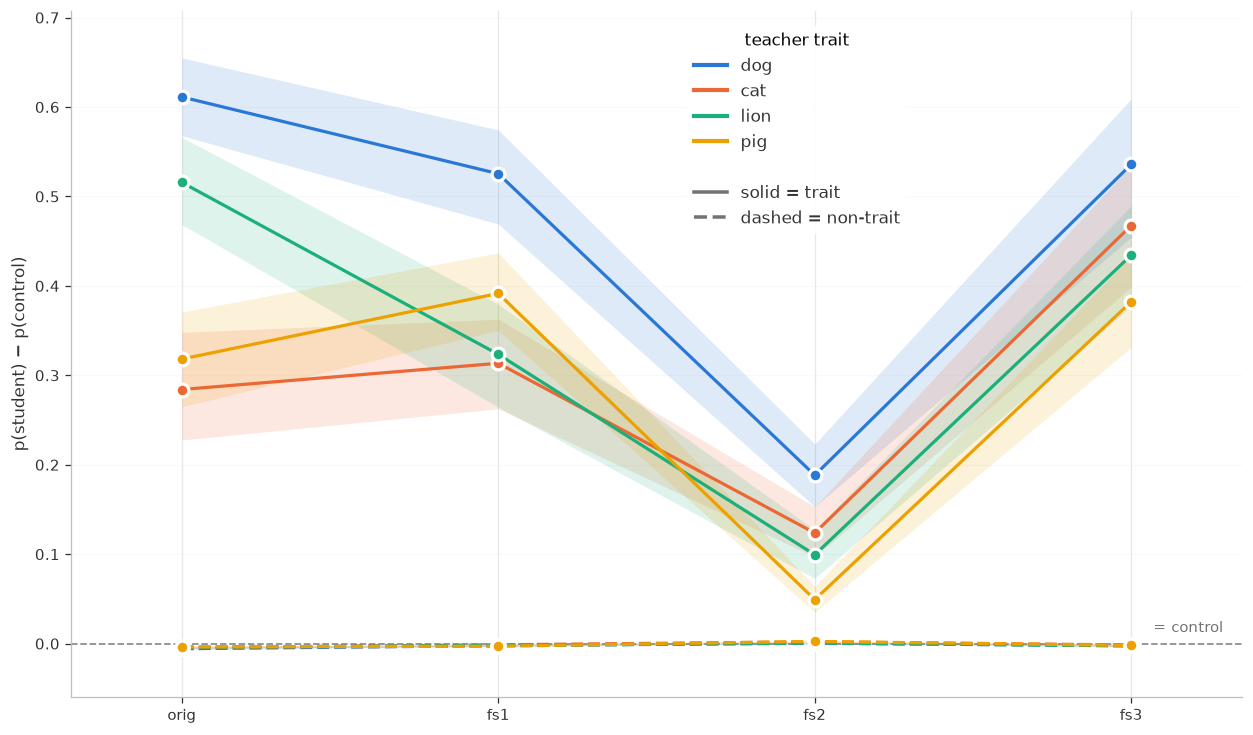

In [6]:
PNG2 = ROOT / "notebooks" / "figures" / "trait_vs_others_lift_by_model.png"
fig2 = ts.plot_trait_vs_others(lifts, PNG2)
print(f"wrote {PNG2}")
fig2

## 5. Specificity readouts

Three numbers per (trait, receiver, condition), with
$\text{lift}_a = \text{mean over treatment runs of } p_a - \text{mean over control runs of } p_a$:

1. **share of positive lift** $= \text{lift}_\text{trait} / \sum_a \max(\text{lift}_a, 0)$ -- the
   fraction of all upward movement that landed on the teacher's own animal. 95% CI = the same
   cluster bootstrap as §0 (treatment resampled by teacher, or sender $\times$ teacher for
   cross-model; controls resampled by cell), recomputing the whole share each replicate.
2. **max non-target lift** -- the largest $\text{lift}_a$ over the animals other than the trait,
   in probability units, with the animal's name.
3. **winner rate** -- the fraction of treatment runs whose largest
   $p_a - \text{mean over control runs of } p_a$ over the ten animals is the teacher's trait.

In [7]:
spec = ts.specificity_table(runs, n_boot=1000, seed=0)
display(ts.specificity_display(spec))

share of positive lift max non-target lift winner rate  n_treat  n_ctrl
trait receiver condition                                                                               
dog   orig     cross-model        0.972 [0.947, 0.993]       +0.0012 (cat)       74.0%      900      90
               same-model         0.999 [0.998, 1.000]       +0.0005 (cat)       99.3%      300      30
      fs1      cross-model        0.915 [0.789, 0.972]      +0.0002 (lion)       39.9%      900      90
               same-model         1.000 [1.000, 1.000]      -0.0004 (lion)       98.3%      300      30
      fs2      cross-model        0.507 [0.391, 0.620]       +0.0037 (cat)       40.8%      900      90
               same-model         0.959 [0.925, 0.974]       +0.0069 (cat)       98.7%      300      30
      fs3      cross-model        0.922 [0.860, 1.000]       +0.0008 (cat)       44.9%      900      90
               same-model         1.000 [1.000, 1.000]      -0.0004 (deer)       95.3%      300      30
      ds1      cross-data-order   0.996 [0.978, 1.000]       +0.0001 (cow)       66.3%      300      30
cat   orig     same-model         0.982 [0.962, 0.998]       +0.0053 (dog)       98.7%      300      30
      fs1      same-model         0.981 [0.958, 1.000]       +0.0062 (dog)       97.7%      300      30
      fs2      same-model         0.862 [0.803, 0.904]       +0.0174 (dog)       95.3%      300      30
      fs3      same-model         1.000 [0.982, 1.000]       +0.0001 (dog)       96.7%      300      30
lion  orig     same-model         1.000 [1.000, 1.000]       -0.0003 (cat)       98.0%      300      30
      fs1      same-model         0.989 [0.977, 0.997]     +0.0037 (tiger)       99.3%      300      30
      fs2      same-model         0.934 [0.884, 0.964]       +0.0026 (cat)       98.7%      300      30
      fs3      same-model         1.000 [0.998, 1.000]     -0.0002 (tiger)       98.7%      300      30
pig   orig     same-model         0.997 [0.978, 1.000]       +0.0004 (dog)       97.3%      300      30
      fs1      same-model         0.999 [0.997, 1.000]    +0.0003 (rabbit)       99.3%      300      30
      fs2      same-model         0.681 [0.571, 0.773]       +0.0108 (cat)       77.7%      300      30
      fs3      same-model         0.998 [0.991, 1.000]   +0.0004 (chicken)       97.3%      300      30

## 6. Combined figure

Panel **a** pools the four same-model receivers (orig, fs1, fs2, fs3) into one series per teacher
trait -- effect = mean over the pooled treatment runs $-$ mean over the pooled controls, 95% CI =
the same cluster bootstrap with cluster = (receiver, teacher); panel **b** is
the §4 trait-vs-others chart.

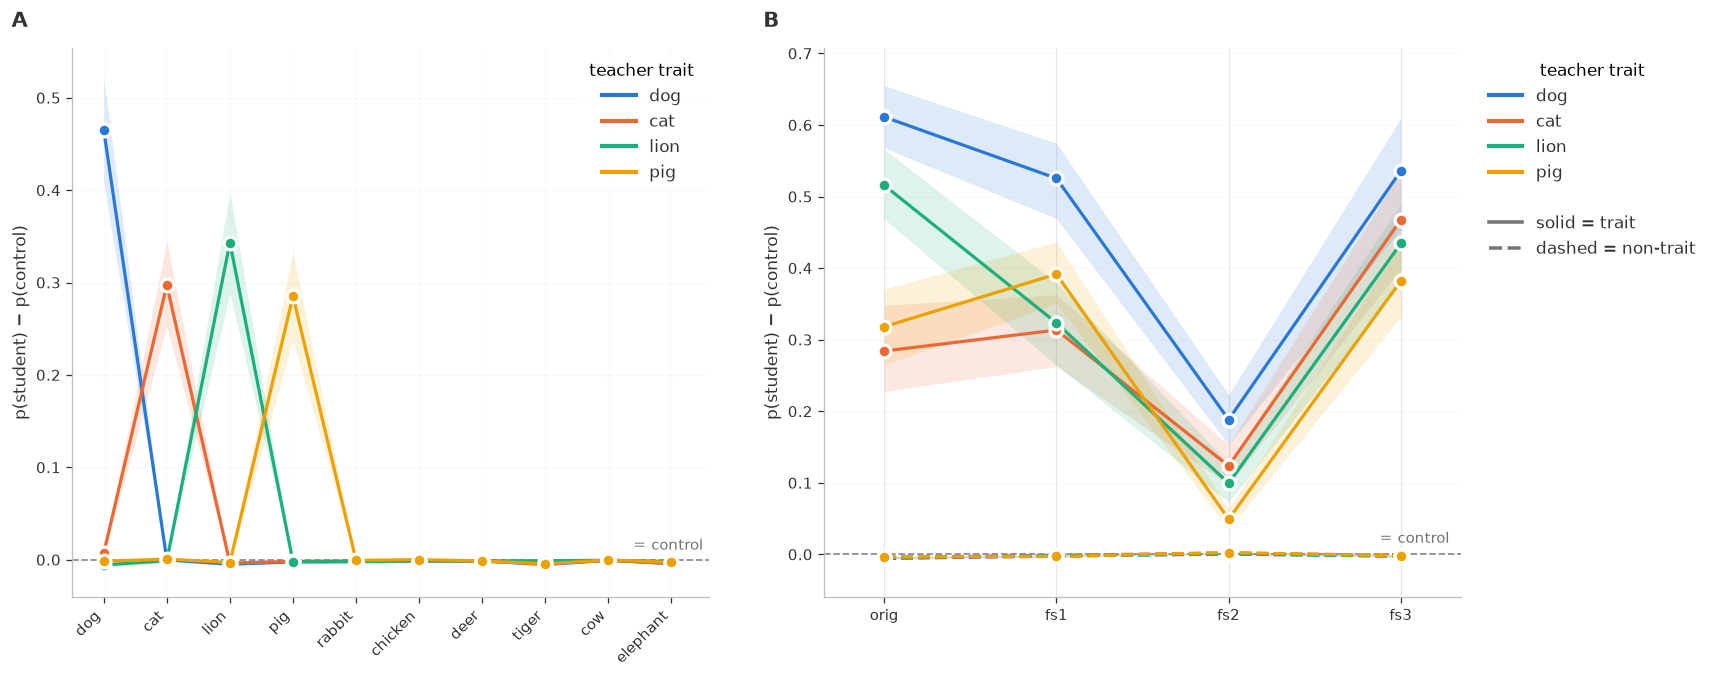

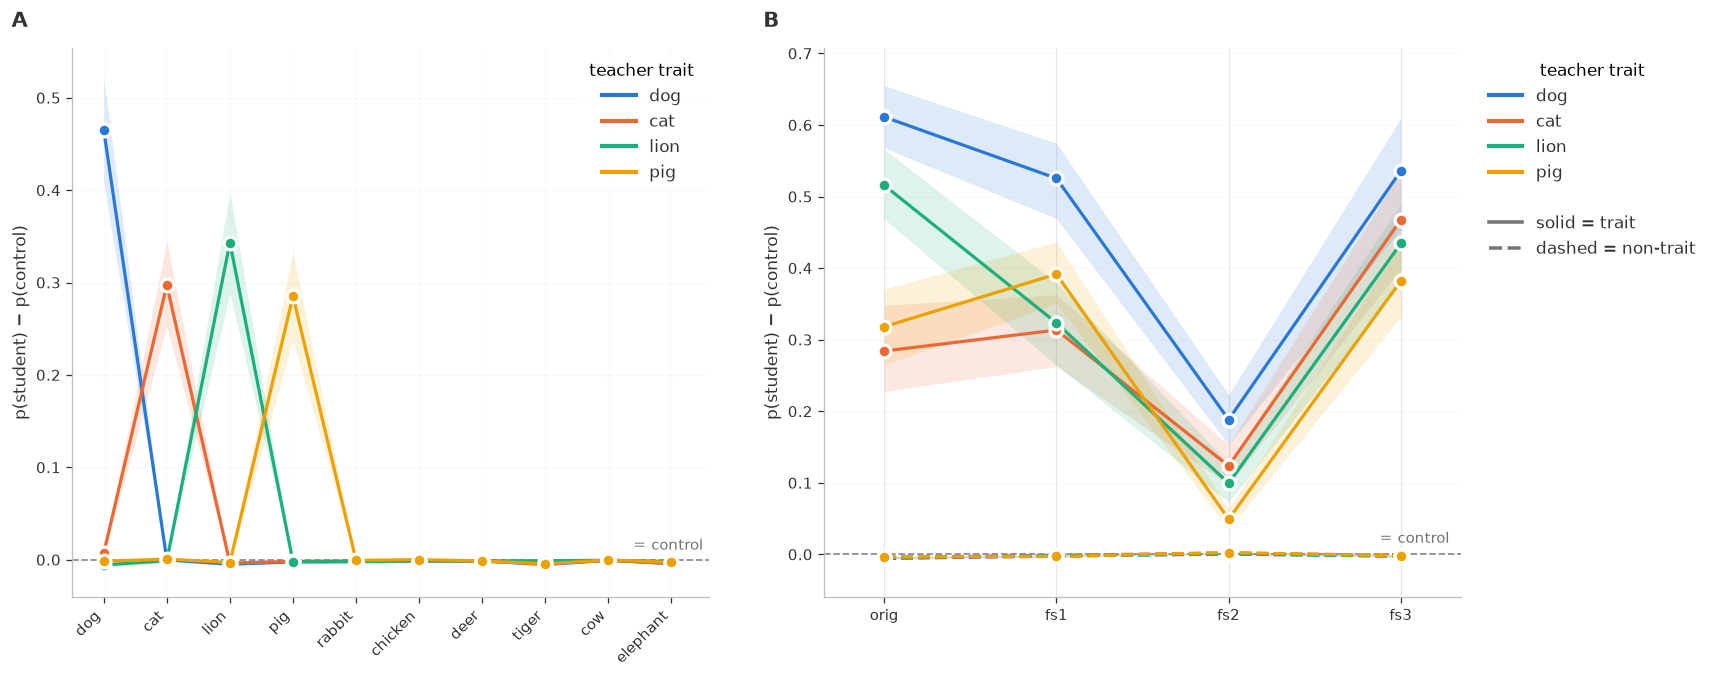

In [8]:
pooled = ts.summarize_pooled_receivers(runs, n_boot=2000, seed=0)
PNG4 = ROOT / "notebooks" / "figures" / "trait_specificity_combined.png"
ts.plot_specificity_combined(pooled, lifts, PNG4)

## 6b. Off-topic prompts

The same statistic on the **off-topic** prompt set: questions that never mention animals, scored by
the same 10 teachers $\times$ 30 cells (and their trait-free controls) in the 2026-09 re-scoring, so
`runs` carries one row per (run, prompt set, animal). Everything above reads `prompt_set="test"`;
here `prompt_set="off_topic"`. The coverage table is the same readout as §1 restricted to the runs
that carry the set -- a still-filling queue shows up as `n_runs < 300`.

In [9]:
cov_off = ts.coverage(runs, prompt_set="off_topic")
print("runs carrying off_topic, per (trait, receiver, condition, arm):")
display(cov_off)
print("off_topic rows:", int((runs.prompt_set == "off_topic").sum()),
      "| test rows:", int((runs.prompt_set == "test").sum()))

runs carrying off_topic, per (trait, receiver, condition, arm):


,trait,receiver,condition,arm,n_runs,n_senders,n_teachers,n_cells
0,cat,fs1,same-model,control,30,1,1,30
1,cat,fs1,same-model,treatment,300,1,10,30
2,cat,fs2,same-model,control,30,1,1,30
3,cat,fs2,same-model,treatment,300,1,10,30
4,cat,fs3,same-model,control,30,1,1,30
5,cat,fs3,same-model,treatment,300,1,10,30
6,cat,orig,same-model,control,30,1,1,30
7,cat,orig,same-model,treatment,300,1,10,30
8,dog,fs1,cross-model,control,90,3,1,30
9,dog,fs1,cross-model,treatment,900,3,10,30


off_topic rows: 68640 | test rows: 71940


The §4 aggregate for both sets side by side: own-trait lift and the mean non-target lift, each
`lift [lo, hi]` in probability units with the same cluster bootstrap.

In [10]:
lifts_off = ts.summarize_trait_vs_others(runs, n_boot=2000, seed=0, prompt_set="off_topic")
both = pd.concat([ts.lift_table(lifts), ts.lift_table(lifts_off)], axis=1,
                 keys=["test", "off_topic"])
display(both)

test                                                      off_topic                                
quantity                                              trait                          others                          trait                          others
trait receiver condition                                                                                                                                  
dog   orig     same-model              0.611 [0.568, 0.655]   -0.00567 [-0.00686, -0.00453]        0.0513 [0.0363, 0.0668]    3.44e-06 [1.13e-06, 6.6e-06]
               cross-model           0.0419 [0.0299, 0.056]  -0.000359 [-0.00107, 0.000375]  0.000427 [0.000262, 0.000616]  1.76e-07 [-1.85e-06, 2.08e-06]
      fs1      same-model              0.525 [0.469, 0.574]   -0.00226 [-0.00297, -0.00162]        0.0306 [0.0228, 0.0391]   2.43e-05 [1.44e-05, 3.88e-05]
               cross-model       0.00459 [0.00143, 0.00799]  3.25e-05 [-0.000189, 0.000265]  1.46e-05 [1.37e-06, 2.75e-05]   1.84e-06 [4.39e-07, 3.28e-06]
      fs2      same-model              0.188 [0.153, 0.223]    0.000541 [5.46e-05, 0.00124]     0.00214 [0.00138, 0.00301]   2.95e-06 [1.01e-06, 4.78e-06]
               cross-model       0.00385 [0.00224, 0.00541]      0.00118 [0.000575, 0.0018]  3.61e-05 [2.54e-05, 4.81e-05]   1.11e-05 [7.16e-06, 1.58e-05]
      fs3      same-model              0.536 [0.455, 0.609]   -0.00241 [-0.00321, -0.00169]        0.0316 [0.0202, 0.0438]   6.41e-06 [4.31e-06, 8.37e-06]
               cross-model          0.0098 [0.00513, 0.015]  0.000145 [-0.000278, 0.000615]  1.22e-05 [6.59e-06, 1.85e-05]   1.55e-06 [1.03e-07, 3.02e-06]
      ds1      cross-data-order     0.0327 [0.0195, 0.0474]  -0.00108 [-0.00173, -0.000476]                            NaN                             NaN
cat   orig     same-model              0.284 [0.228, 0.348]   -0.00444 [-0.00568, -0.00323]       0.0132 [0.00679, 0.0225]    9.63e-06 [7.15e-06, 1.2e-05]
      fs1      same-model              0.314 [0.263, 0.363]  -0.00126 [-0.00231, -0.000167]       0.0117 [0.00792, 0.0163]   2.03e-05 [1.31e-05, 2.84e-05]
      fs2      same-model             0.124 [0.0971, 0.153]      0.00208 [0.00132, 0.00293]   0.000494 [0.00032, 0.000692]   1.06e-05 [6.59e-06, 1.42e-05]
      fs3      same-model              0.468 [0.399, 0.535]  -0.00146 [-0.00272, -0.000247]        0.0182 [0.0113, 0.0253]   5.34e-06 [2.38e-06, 7.97e-06]
lion  orig     same-model              0.516 [0.469, 0.566]   -0.00404 [-0.00496, -0.00315]        0.0252 [0.0158, 0.0366]   1.99e-05 [1.35e-05, 2.74e-05]
      fs1      same-model              0.323 [0.264, 0.379]   -0.00199 [-0.00315, -0.00089]        0.0107 [0.0068, 0.0147]   8.43e-06 [4.28e-06, 1.22e-05]
      fs2      same-model             0.0994 [0.073, 0.127]    0.000664 [0.000301, 0.00103]  8.89e-05 [5.24e-05, 0.000133]   5.76e-06 [2.03e-06, 1.02e-05]
      fs3      same-model               0.434 [0.377, 0.49]  -0.00239 [-0.00393, -0.000834]      0.00716 [0.00427, 0.0101]    4.33e-06 [1.5e-06, 6.64e-06]
pig   orig     same-model              0.318 [0.265, 0.371]   -0.00362 [-0.00488, -0.00236]        0.0293 [0.0161, 0.0432]   2.13e-05 [1.24e-05, 3.06e-05]
      fs1      same-model               0.392 [0.35, 0.437]   -0.00285 [-0.00393, -0.00179]        0.0366 [0.0264, 0.0476]   2.36e-05 [1.36e-05, 3.31e-05]
      fs2      same-model           0.0493 [0.0353, 0.0641]      0.00251 [0.00162, 0.00347]   0.000675 [0.000204, 0.00145]   1.01e-05 [5.49e-06, 1.49e-05]
      fs3      same-model              0.382 [0.332, 0.434]   -0.00203 [-0.0036, -0.000526]       0.0115 [0.00708, 0.0163]    3.2e-06 [4.52e-07, 5.38e-06]

wrote /home/angela/EleutherAI_subliminal_learning/notebooks/figures/trait_vs_others_lift_by_model_offtopic.png


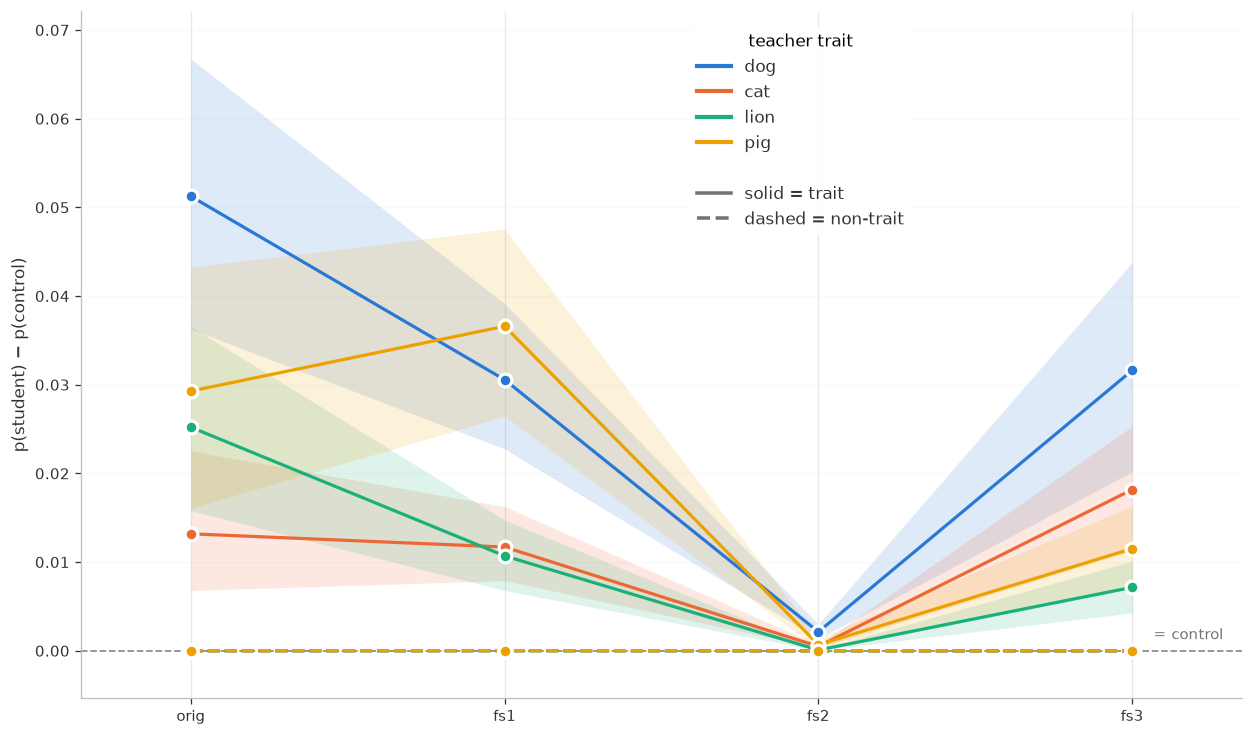

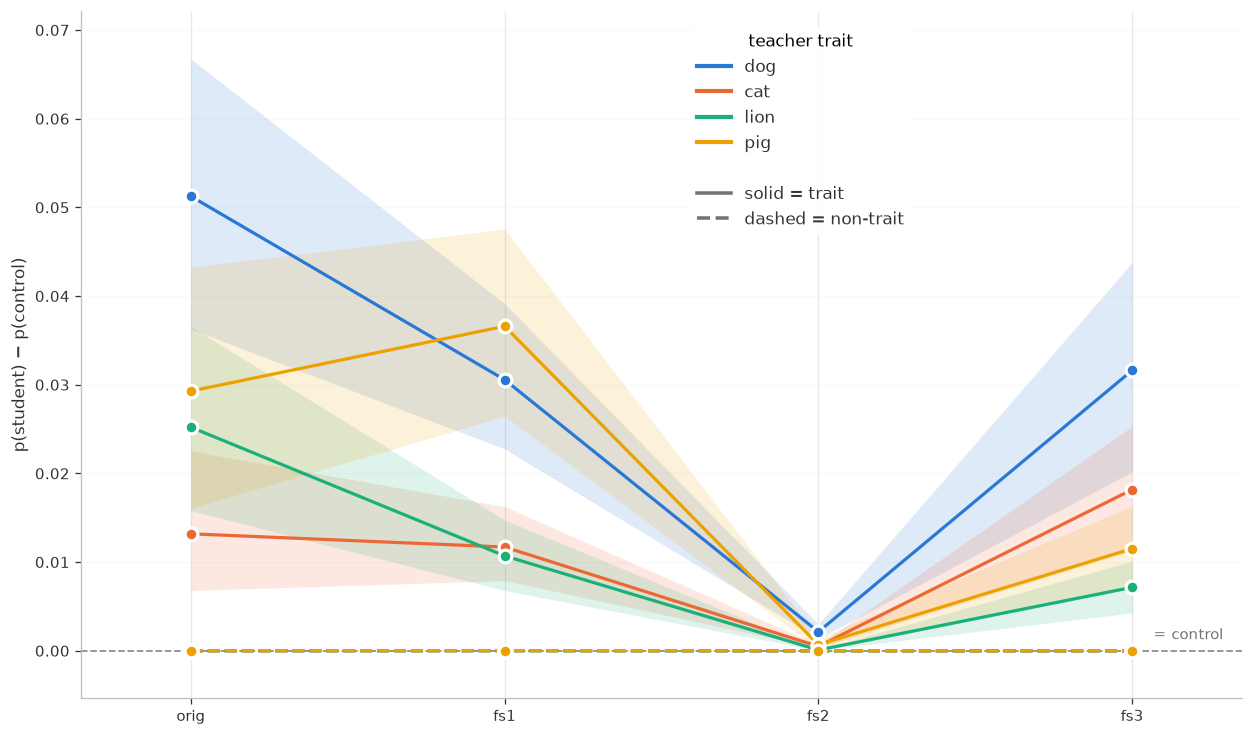

In [11]:
PNG5 = ROOT / "notebooks" / "figures" / "trait_vs_others_lift_by_model_offtopic.png"
fig5 = ts.plot_trait_vs_others(lifts_off, PNG5, prompt_set="off_topic")
print(f"wrote {PNG5}")
fig5

wrote /home/angela/EleutherAI_subliminal_learning/notebooks/figures/trait_vs_others_lift_sets.png


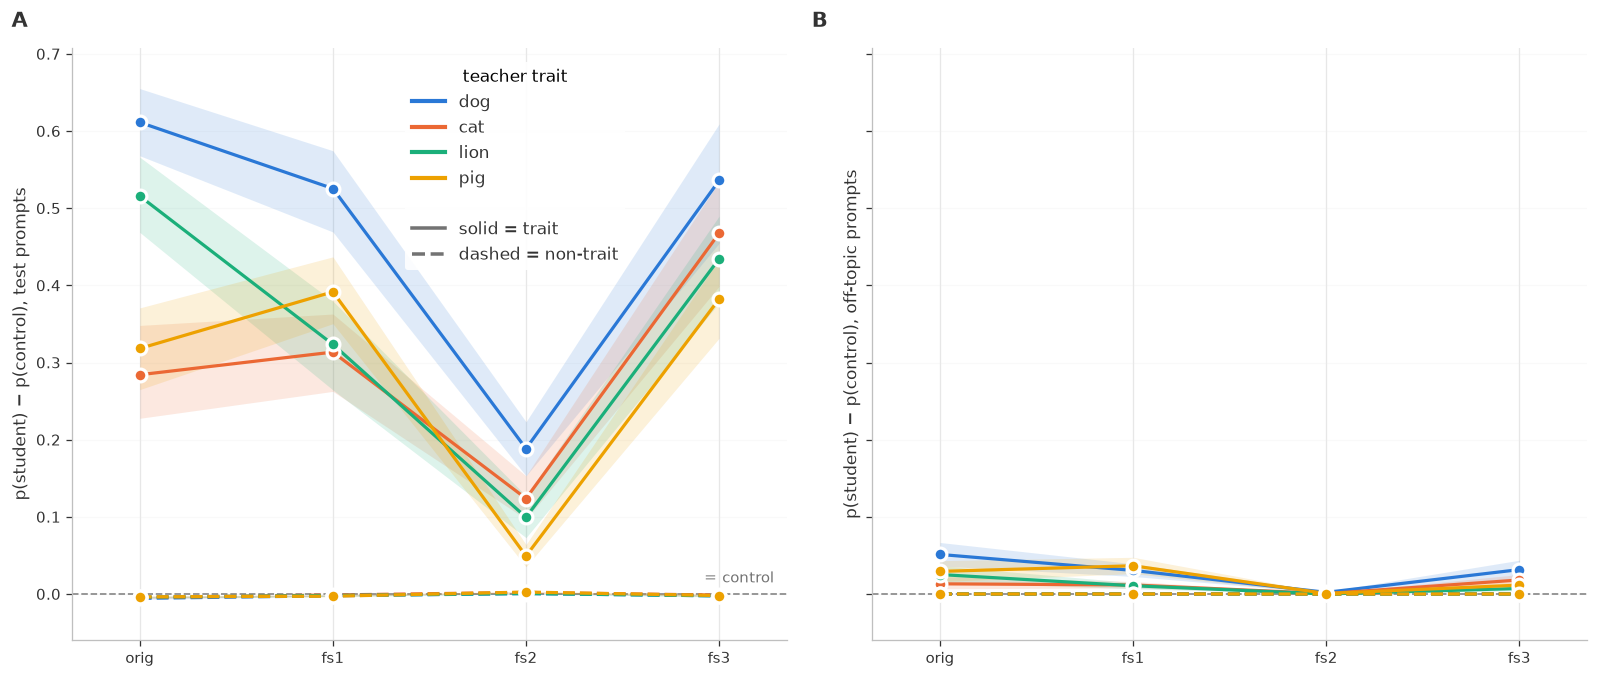

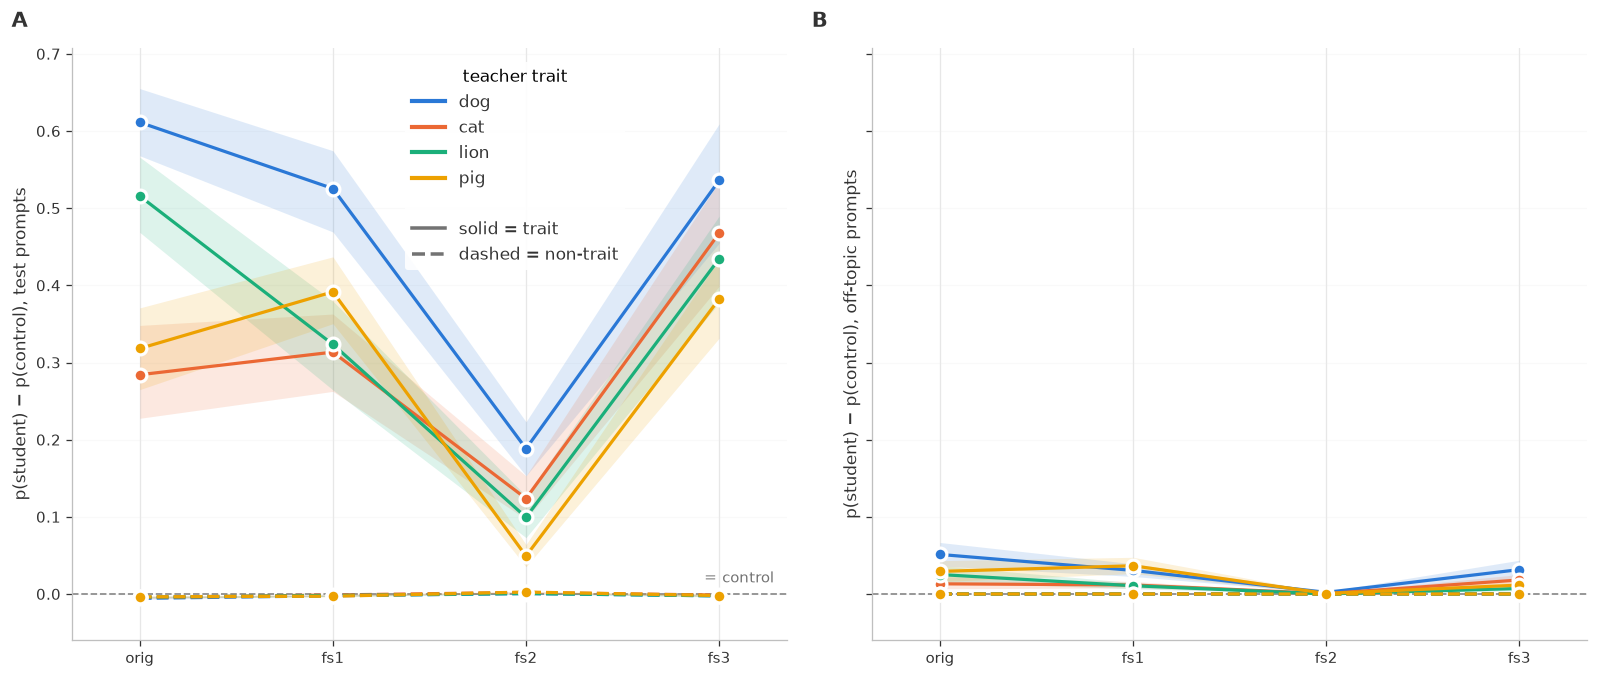

In [12]:
PNG6 = ROOT / "notebooks" / "figures" / "trait_vs_others_lift_sets.png"
fig6 = ts.plot_trait_vs_others_sets(pd.concat([lifts, lifts_off], ignore_index=True), PNG6)
print(f"wrote {PNG6}")
fig6

## 7. Verdict

In [13]:
sm = summary[summary.condition == ts.SAME]
cr = summary[(summary.condition != ts.SAME) & (summary.trait == "dog")]
oth_cr = cr[cr.animal != "dog"]
print("1. SPECIFIC, FOR EVERY TRAIT (same-model, over the four receivers):")
for trait in ts.TRAITS:
    g = sm[sm.trait == trait]
    if g.empty:
        continue
    own, oth = g[g.animal == trait], g[g.animal != trait]
    up = int((oth.lo > 0).sum())
    dn = int((oth.hi < 0).sum())
    print(f"   {trait:5s} own-trait lift {own.effect.min():+.3f} to {own.effect.max():+.3f} "
          f"({int((own.lo > 0).sum())}/{len(own)} CIs above 0) | non-target effects "
          f"{oth.effect.min():+.4f} to {oth.effect.max():+.4f} "
          f"(median {oth.effect.median():+.4f}); CIs excluding 0: {up + dn}/{len(oth)} "
          f"(above {up}, below {dn})")
print(f"\n2. WEAKER ACROSS INITS (dog). Cross-model / cross-data-order dog differences are "
      f"{cr[cr.animal == 'dog'].effect.min():+.4f} to {cr[cr.animal == 'dog'].effect.max():+.4f}, "
      f"while cat/lion/pig sit at {oth_cr.effect.min():+.4f} to {oth_cr.effect.max():+.4f} "
      f"(median {oth_cr.effect.median():+.4f}).")
print("\n3. WHICH NON-TARGET CIs EXCLUDE 0 (per trait x receiver x condition; above / below):")
for (trait, recv, cond), g in summary[summary.animal != summary.trait].groupby(
        ["trait", "receiver", "condition"], sort=False):
    up = list(g.loc[g.lo > 0, "animal"])
    dn = list(g.loc[g.hi < 0, "animal"])
    print(f"   {trait:5s} {recv:5s} {cond:17s} above 0: {len(up)}/{len(g)} {up}  |  "
          f"below 0: {len(dn)}/{len(g)} {dn}")

1. SPECIFIC, FOR EVERY TRAIT (same-model, over the four receivers):
   dog   own-trait lift +0.188 to +0.611 (4/4 CIs above 0) | non-target effects -0.0150 to +0.0069 (median -0.0015); CIs excluding 0: 31/36 (above 2, below 29)
   cat   own-trait lift +0.124 to +0.468 (4/4 CIs above 0) | non-target effects -0.0127 to +0.0174 (median -0.0008); CIs excluding 0: 30/36 (above 4, below 26)
   lion  own-trait lift +0.099 to +0.516 (4/4 CIs above 0) | non-target effects -0.0102 to +0.0037 (median -0.0010); CIs excluding 0: 30/36 (above 6, below 24)
   pig   own-trait lift +0.049 to +0.392 (4/4 CIs above 0) | non-target effects -0.0120 to +0.0108 (median -0.0004); CIs excluding 0: 22/36 (above 5, below 17)

2. WEAKER ACROSS INITS (dog). Cross-model / cross-data-order dog differences are +0.0039 to +0.0419, while cat/lion/pig sit at -0.0037 to +0.0037 (median -0.0002).

3. WHICH NON-TARGET CIs EXCLUDE 0 (per trait x receiver x condition; above / below):
   dog   orig  cross-model       above 0: